# Deep Learning – Assignment 2 (CO2): Complete Colab Notebook
**Q1–Q7 | Google Colab | Seed = 42**

Run all cells from top to bottom. GPU is recommended but not mandatory. The notebook produces plots and CSV evidence files. After execution, download the `.ipynb` with outputs and share its Colab link so the final report can use the actual measured results.

**Dataset notes:** Q1, Q2 and Q4 use reproducible synthetic scenario data because no dataset was supplied for those scenarios. Q3, Q5, Q6 and Q7 use Fashion-MNIST. Fashion-MNIST is a practical image benchmark substitute, not a plant-leaf or wildlife dataset. State this limitation in the report. Q2 uses NumPy only for all forward/backward calculations and gradient checking.

## 0. Setup and shared utilities

In [1]:
import os, time, math, random, glob, zipfile, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
SEED=42
os.environ["PYTHONHASHSEED"]=str(SEED)
random.seed(SEED); np.random.seed(SEED)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
tf.keras.utils.set_random_seed(SEED)
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, mean_absolute_error
print("Python",platform.python_version(),"TensorFlow",tf.__version__,"NumPy",np.__version__)
print("Seed",SEED,"GPU",tf.config.list_physical_devices("GPU"))

def metrics_binary(y,p):
    pred=(np.asarray(p).ravel()>=0.5).astype(int)
    return dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),
                recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0))
def plot_hist(h,title):
    fig,ax=plt.subplots(1,2,figsize=(10,3))
    ax[0].plot(h.history["loss"],label="train")
    if "val_loss" in h.history: ax[0].plot(h.history["val_loss"],label="validation")
    ax[0].set_title(title+" loss"); ax[0].legend()
    if "accuracy" in h.history: ax[1].plot(h.history["accuracy"],label="train")
    if "val_accuracy" in h.history: ax[1].plot(h.history["val_accuracy"],label="validation")
    ax[1].set_title(title+" accuracy"); ax[1].legend()
    plt.show()
def export(df,name):
    display(df); df.to_csv(name,index=False); print("Saved",name)

Python 3.13.18 TensorFlow 2.21.0 NumPy 2.1.3
Seed 42 GPU []


# Q1 – Hidden Units: Activation Function vs Depth (6 marks)

**Prediction:** sigmoid derivative is `σ(z)(1−σ(z)) ≤ 0.25`; tanh derivative is `1−tanh²(z) ≤ 1`; ReLU derivative is 1 for positive inputs and 0 for negative inputs. Backpropagation multiplies activation derivatives across layers, so sigmoid/tanh may produce vanishing gradients at depth, while ReLU with He initialization often preserves active-path gradients. Poor initialization can still cause unstable or weak gradients.

Scenario data: 2,000 synthetic credit-card-like records, 20 features, stratified 60/20/20 train/validation/test split. Synthetic data is not real financial data.

Records/features (2000, 20) splits (1200, 20) (400, 20) (400, 20)


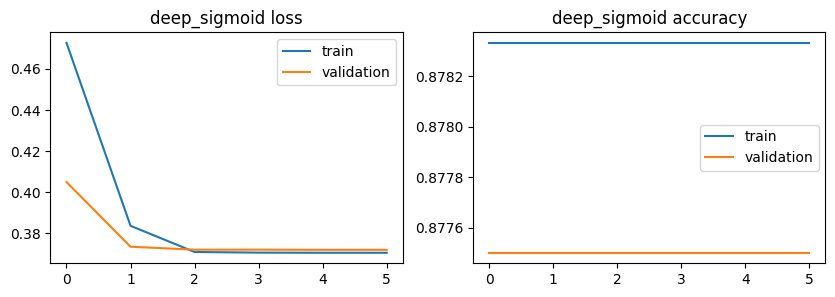

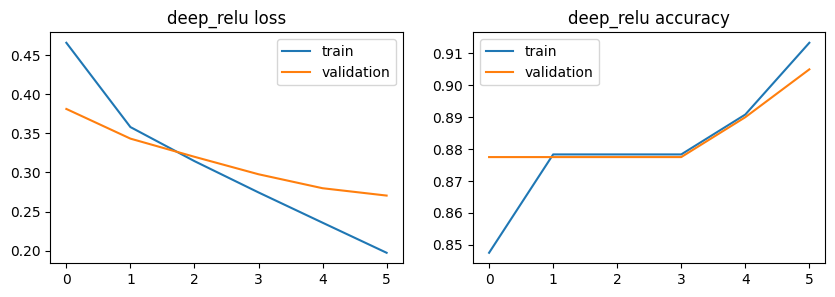

,config,activation,depth,poor_init,train_loss,val_loss,accuracy,precision,recall,f1
0,shallow_sigmoid,sigmoid,2,False,0.357991,0.354544,0.8775,0.000000,0.000000,0.000000
1,deep_sigmoid,sigmoid,8,False,0.370424,0.371874,0.8775,0.000000,0.000000,0.000000
2,deep_tanh,tanh,8,False,0.157082,0.192501,0.9400,0.804878,0.673469,0.733333
3,deep_relu,relu,8,False,0.197528,0.270540,0.9150,0.741935,0.469388,0.575000
4,deep_relu_poor_init,relu,8,True,294016.375000,260770.875000,0.7875,0.200000,0.244898,0.220183


Saved Q1_activation_results.csv


,config,layer,gradient_norm
0,shallow_sigmoid,h1,2.520920e-02
1,shallow_sigmoid,h2,4.861811e-01
2,deep_sigmoid,h1,3.606410e-06
3,deep_sigmoid,h2,3.366700e-05
4,deep_sigmoid,h3,1.607311e-04
5,deep_sigmoid,h4,5.675693e-04
6,deep_sigmoid,h5,2.373583e-03
7,deep_sigmoid,h6,1.212680e-02
8,deep_sigmoid,h7,5.454753e-02
9,deep_sigmoid,h8,2.338809e-01


Saved Q1_layer_gradient_norms.csv


,layer,inactive_fraction
0,h1,0.498901
1,h2,0.610657
2,h3,0.510193
3,h4,0.512085
4,h5,0.517639
5,h6,0.596252
6,h7,0.566589
7,h8,0.550354


Saved Q1_relu_inactive_fraction.csv
Recommendation to investigate for >=8 layers: ReLU + He initialization; validate gradient norms, dead-unit fraction and held-out metrics on real data.


In [3]:
X1,y1=make_classification(n_samples=2000,n_features=20,n_informative=12,n_redundant=4,
                          weights=[0.88,0.12],random_state=SEED)
X1=StandardScaler().fit_transform(X1).astype("float32"); y1=y1.astype("float32")
X1tr,X1tmp,y1tr,y1tmp=train_test_split(X1,y1,test_size=.4,stratify=y1,random_state=SEED)
X1v,X1te,y1v,y1te=train_test_split(X1tmp,y1tmp,test_size=.5,stratify=y1tmp,random_state=SEED)
print("Records/features",X1.shape,"splits",X1tr.shape,X1v.shape,X1te.shape)
def q1build(act,depth,poor=False):
    inp=keras.Input((20,)); x=inp
    for i in range(depth):
        init=keras.initializers.RandomNormal(stddev=2.,seed=SEED+i) if poor else (
            keras.initializers.HeNormal(seed=SEED+i) if act=="relu" else keras.initializers.GlorotUniform(seed=SEED+i))
        x=layers.Dense(32,activation=act,kernel_initializer=init,name=f"h{i+1}")(x)
    out=layers.Dense(1,activation="sigmoid")(x)
    m=keras.Model(inp,out); m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
    return m
def q1grads(m):
    with tf.GradientTape() as tape:
        p=m(X1tr[:128],training=True)
        loss=tf.reduce_mean(keras.losses.binary_crossentropy(y1tr[:128][:, None],p))
    gs=tape.gradient(loss,m.trainable_variables)
    ans={}
    for i,l in enumerate([l for l in m.layers if l.name.startswith("h")]):
        ans[l.name]=float(tf.linalg.global_norm([gs[2*i]]).numpy())
    return ans
q1spec=[("shallow_sigmoid","sigmoid",2,False),("deep_sigmoid","sigmoid",8,False),
        ("deep_tanh","tanh",8,False),("deep_relu","relu",8,False),("deep_relu_poor_init","relu",8,True)]
rows=[]; grows=[]
for name,act,d,poor in q1spec:
    tf.keras.backend.clear_session(); m=q1build(act,d,poor); g=q1grads(m)
    h=m.fit(X1tr,y1tr,validation_data=(X1v,y1v),epochs=6,batch_size=64,verbose=0)
    p=m.predict(X1te,verbose=0).ravel()
    rows.append(dict(config=name,activation=act,depth=d,poor_init=poor,train_loss=h.history["loss"][-1],
                     val_loss=h.history["val_loss"][-1],**metrics_binary(y1te,p)))
    grows += [dict(config=name,layer=k,gradient_norm=v) for k,v in g.items()]
    if name in ["deep_sigmoid","deep_relu"]: plot_hist(h,name)
q1results=pd.DataFrame(rows); q1grad=pd.DataFrame(grows)
export(q1results,"Q1_activation_results.csv"); export(q1grad,"Q1_layer_gradient_norms.csv")
# Dead ReLU fraction
tf.keras.backend.clear_session(); mr=q1build("relu",8)
mr.fit(X1tr,y1tr,epochs=2,batch_size=64,verbose=0)
dead=[]
for l in [l for l in mr.layers if l.name.startswith("h")]:
    probe=keras.Model(mr.input,l.output)
    dead.append(dict(layer=l.name,inactive_fraction=float(np.mean(probe(X1tr[:512],training=False).numpy()<=0))))
export(pd.DataFrame(dead),"Q1_relu_inactive_fraction.csv")
print("Recommendation to investigate for >=8 layers: ReLU + He initialization; validate gradient norms, dead-unit fraction and held-out metrics on real data.")

# Q2 – NumPy Backpropagation and Gradient Checking (4 marks)

Computational graph: `x → z1=xW1+b1 → a1=sigmoid(z1) → z2=a1W2+b2 → p=sigmoid(z2) → binary cross-entropy`.

For batch size `m`: `δ2=(p−y)/m`; `dW2=a1ᵀδ2`; `db2=Σδ2`; `δ1=(δ2W2ᵀ)⊙a1(1−a1)`; `dW1=xᵀδ1`; `db1=Σδ1`. The NumPy code below has no autodiff. A relative error below approximately `1e-5` is commonly a reasonable finite-difference check for this small double-precision example; report the observed values and ε.

In [4]:
rng=np.random.default_rng(SEED)
X2=rng.normal(size=(160,4)); X2=(X2-X2.mean(0))/(X2.std(0)+1e-9)
w=np.array([.25,.16,.42,.10]); pr=1/(1+np.exp(-(X2@w-.3)))
y2=(rng.random(160)<pr).astype(float).reshape(-1,1)
X2=X2.astype(float); y2=y2.astype(float)
rng=np.random.default_rng(SEED)
P={"W1":rng.normal(0,.2,(4,5)),"b1":np.zeros((1,5)),
   "W2":rng.normal(0,.2,(5,1)),"b2":np.zeros((1,1))}
def sig(z): return 1/(1+np.exp(-np.clip(z,-40,40)))
def fwd(x,p):
    a=sig(x@p["W1"]+p["b1"]); out=sig(a@p["W2"]+p["b2"])
    return out,a
def loss(x,y,p):
    q,_=fwd(x,p); e=1e-12
    return float(-np.mean(y*np.log(q+e)+(1-y)*np.log(1-q+e)))
def back(x,y,p,bug=False):
    q,a=fwd(x,p); m=len(x); d2=(q-y)/m
    dW2=a.T@d2; db2=d2.sum(0,keepdims=True)
    d1=d2@p["W2"].T
    if not bug: d1=d1*a*(1-a) # deliberate bug omits this term
    return {"W1":x.T@d1,"b1":d1.sum(0,keepdims=True),"W2":dW2,"b2":db2}
def numeric(x,y,p,eps):
    out={}
    for k in p:
        g=np.zeros_like(p[k])
        for ix in np.ndindex(p[k].shape):
            old=p[k][ix]; p[k][ix]=old+eps; plus=loss(x,y,p)
            p[k][ix]=old-eps; minus=loss(x,y,p); p[k][ix]=old
            g[ix]=(plus-minus)/(2*eps)
        out[k]=g
    return out
def relerr(a,b): return np.linalg.norm(a-b)/(np.linalg.norm(a)+np.linalg.norm(b)+1e-12)
xb,yb=X2[:12],y2[:12]
for eps in [1e-5,1e-6]:
    an=back(xb,yb,P); nu=numeric(xb,yb,P,eps)
    print("epsilon",eps,{k:relerr(an[k],nu[k]) for k in P})
# NumPy gradient descent training
p={k:v.copy() for k,v in P.items()}
initial=loss(X2,y2,p)
for epoch in range(300):
    gs=back(X2,y2,p)
    for k in p: p[k]-=.15*gs[k]
print("NumPy training loss: initial",initial,"final",loss(X2,y2,p))
# Bug detection
bg=back(xb,yb,P,bug=True); nu=numeric(xb,yb,P,1e-5)
bugtable=pd.DataFrame([dict(parameter=k,buggy_relative_error=relerr(bg[k],nu[k])) for k in P])
export(bugtable,"Q2_bug_gradient_check.csv")
print("Missing sigmoid derivative affects hidden parameter groups W1 and b1; W2 and b2 should still match.")

epsilon 1e-05 {'W1': np.float64(4.730471145145519e-10), 'b1': np.float64(5.088291732363891e-10), 'W2': np.float64(1.4959270140461166e-11), 'b2': np.float64(7.830149727173246e-12)}
epsilon 1e-06 {'W1': np.float64(6.273716295447912e-09), 'b1': np.float64(5.8805736248135436e-09), 'W2': np.float64(2.1513418181290662e-10), 'b2': np.float64(2.7187625936994055e-11)}
NumPy training loss: initial 0.6929976550274081 final 0.6907191308357812


,parameter,buggy_relative_error
0,W1,6.033060e-01
1,b1,6.035610e-01
2,W2,1.495927e-11
3,b2,7.830150e-12


Saved Q2_bug_gradient_check.csv
Missing sigmoid derivative affects hidden parameter groups W1 and b1; W2 and b2 should still match.


# Q3 – Overfitting and Regularization (6 marks)

**Dataset substitution:** Fashion-MNIST binary classes 0 (T-shirt/top) and 1 (trouser) are used as an image benchmark proxy. It is not plant-leaf data. The deliberately small training subset creates a controlled overfitting opportunity. Conditions: larger-data/small model, small-data/large model, and small-data/large model with 15% label noise. Compare L2, dropout, early stopping, augmentation, batch normalization and combined augmentation+dropout.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


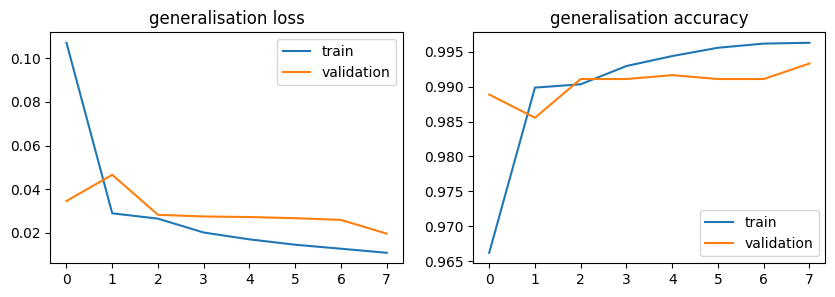

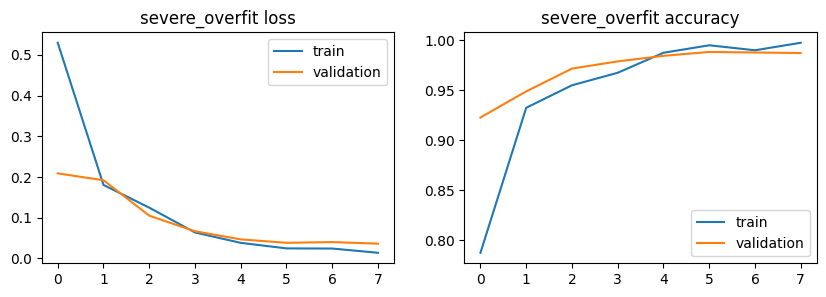

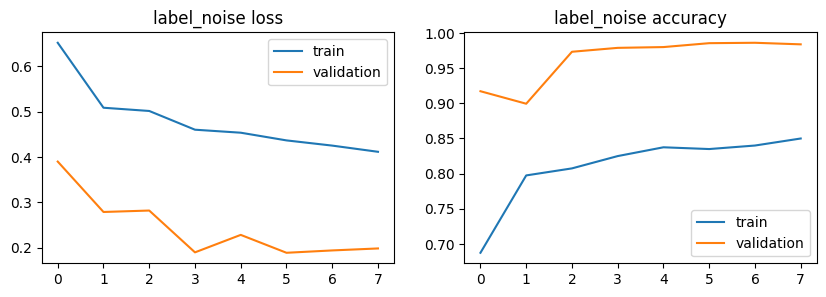

,condition,n_train,capacity,noise,train_accuracy,val_accuracy,accuracy_gap,min_val_loss_epoch
0,generalisation,8400,small,0.00,0.997738,0.993333,0.004405,8
1,severe_overfit,400,large,0.00,0.997500,0.987222,0.010278,8
2,label_noise,400,large,0.15,0.852500,0.983889,-0.131389,6


Saved Q3_conditions.csv


In [5]:
(x3,y3),_=keras.datasets.fashion_mnist.load_data()
x3=(x3.astype("float32")/255.)[...,None]; y3=(y3==1).astype("int64")
idx=np.where(np.isin(np.array(keras.datasets.fashion_mnist.load_data()[0][1]),[0,1]))[0] if False else None
# Reload labels correctly and select original classes 0 and 1
(_,y3raw),_=keras.datasets.fashion_mnist.load_data()
mask=np.isin(y3raw,[0,1]); x3=x3[mask]; y3=(y3raw[mask]==1).astype("int64")
x3tr,x3tmp,y3tr,y3tmp=train_test_split(x3,y3,test_size=.30,stratify=y3,random_state=SEED)
x3v,x3te,y3v,y3te=train_test_split(x3tmp,y3tmp,test_size=.5,stratify=y3tmp,random_state=SEED)
xs,ys=x3tr[:400],y3tr[:400]
def q3model(big=False,reg="none"):
    inp=keras.Input((28,28,1)); x=inp
    if reg in ["aug","combined"]:
        x=layers.RandomTranslation(.08,.08)(x); x=layers.RandomRotation(.05)(x)
    fs=[64,128,128] if big else [16,32]
    for f in fs:
        if reg=="bn":
            x=layers.Conv2D(f,3,padding="same",use_bias=False)(x); x=layers.BatchNormalization()(x); x=layers.Activation("relu")(x)
        else:
            x=layers.Conv2D(f,3,padding="same",activation="relu",
                kernel_regularizer=regularizers.l2(.001) if reg=="l2" else None)(x)
        x=layers.MaxPooling2D()(x)
    x=layers.Flatten()(x); x=layers.Dense(256 if big else 64,activation="relu")(x)
    if reg in ["drop","combined"]: x=layers.Dropout(.5)(x)
    out=layers.Dense(1,activation="sigmoid")(x)
    m=keras.Model(inp,out); m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
    return m
conditions=[("generalisation",x3tr,y3tr,False,0),("severe_overfit",xs,ys,True,0)]
yn=ys.copy(); rg=np.random.default_rng(SEED); flip=rg.choice(len(yn),int(.15*len(yn)),replace=False); yn[flip]=1-yn[flip]
conditions.append(("label_noise",xs,yn,True,.15))
cr=[]
for name,xx,yy,big,nz in conditions:
    m=q3model(big); h=m.fit(xx,yy,validation_data=(x3v,y3v),epochs=8,batch_size=64,verbose=0)
    ta=m.evaluate(xx,yy,verbose=0)[1]; va=m.evaluate(x3v,y3v,verbose=0)[1]
    cr.append(dict(condition=name,n_train=len(xx),capacity="large" if big else "small",noise=nz,
                   train_accuracy=ta,val_accuracy=va,accuracy_gap=ta-va,
                   min_val_loss_epoch=int(np.argmin(h.history["val_loss"])+1)))
    plot_hist(h,name)
export(pd.DataFrame(cr),"Q3_conditions.csv")

,regularizer,epochs,train_loss,val_loss,train_accuracy,val_accuracy,accuracy_gap,min_val_loss_epoch,weight_norm,seconds
0,none,12,0.002068,0.041225,1.000,0.988889,0.011111,11,26.154699,61.290163
1,l2,12,0.112616,0.151611,1.000,0.986667,0.013333,11,23.324213,64.852504
2,drop,12,0.007318,0.038971,1.000,0.988333,0.011667,9,26.269655,62.400920
3,early,12,0.006925,0.034219,1.000,0.990000,0.010000,10,26.079603,63.867194
4,aug,12,0.037484,0.052378,0.985,0.982222,0.002778,8,26.088602,55.587284
5,bn,12,1.108752,1.108766,0.500,0.500000,0.000000,1,37.668835,68.927791
6,combined,12,0.034854,0.044575,0.990,0.988333,0.001667,12,26.306183,59.964841


Saved Q3_regularizer_comparison.csv


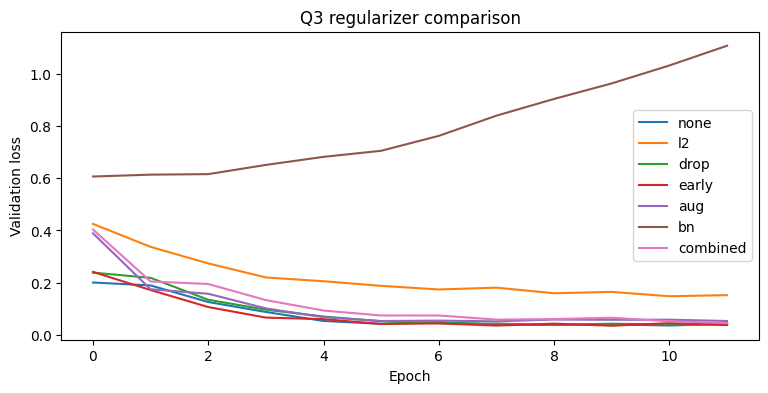

Use the measured gap, validation loss, minimum-loss epoch and weight norm to explain which regularizer helped most; stronger regularization can also increase bias.


In [6]:
# Regularizer experiment on same small training subset
def q3regmodel(reg):
    return q3model(big=True,reg=reg)
rr=[]; histories={}
for reg in ["none","l2","drop","early","aug","bn","combined"]:
    tf.keras.backend.clear_session(); m=q3regmodel("none" if reg in ["none","early"] else reg)
    cb=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=2,restore_best_weights=True)] if reg=="early" else []
    st=time.time(); h=m.fit(xs,ys,validation_data=(x3v,y3v),epochs=12,batch_size=64,verbose=0,callbacks=cb)
    tl,ta=m.evaluate(xs,ys,verbose=0); vl,va=m.evaluate(x3v,y3v,verbose=0)
    wn=float(np.sqrt(sum(np.sum(w*w) for w in m.get_weights())))
    rr.append(dict(regularizer=reg,epochs=len(h.history["loss"]),train_loss=tl,val_loss=vl,
                   train_accuracy=ta,val_accuracy=va,accuracy_gap=ta-va,
                   min_val_loss_epoch=int(np.argmin(h.history["val_loss"])+1),weight_norm=wn,seconds=time.time()-st))
    histories[reg]=h.history
export(pd.DataFrame(rr),"Q3_regularizer_comparison.csv")
plt.figure(figsize=(9,4))
for k,h in histories.items(): plt.plot(h["val_loss"],label=k)
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("Q3 regularizer comparison"); plt.legend(); plt.show()
print("Use the measured gap, validation loss, minimum-loss epoch and weight norm to explain which regularizer helped most; stronger regularization can also increase bias.")

# Q4 – Optimizer Comparison (6 marks)

Synthetic hourly electricity-demand-like regression data is generated reproducibly (8,000 records) and split chronologically 70/15/15. Update rules:
- SGD: `θ←θ−ηg`
- Momentum: `v←βv+g; θ←θ−ηv`
- RMSProp: `s←ρs+(1−ρ)g²; θ←θ−ηg/(√s+ε)`
- Adam: bias-corrected first and second moments, `θ←θ−ηm̂/(√v̂+ε)`

Run four optimizers × three learning rates × two batch sizes, with the same network and epoch budget.

In [7]:
rng=np.random.default_rng(SEED); n=8000; t=np.arange(n); hour=t%24; day=(t//24)%7
season=np.sin(2*np.pi*t/(24*365))
temp=25+7*np.sin(2*np.pi*(hour-14)/24)+4*np.sin(2*np.pi*t/(24*30))+rng.normal(0,1.5,n)
demand=100+18*np.sin(2*np.pi*(hour-8)/24)+8*(day<5)+.8*(temp-25)+10*season+rng.normal(0,3,n)
lag1=np.r_[demand[0],demand[:-1]]; lag24=np.r_[demand[:24],demand[:-24]]
X4=np.column_stack([hour,day,temp,lag1,lag24,season]).astype("float32"); y4=demand.astype("float32")
a=int(.7*n); b=int(.85*n)
A,B,C=X4[:a],X4[a:b],X4[b:]; ya,yb,yc=y4[:a],y4[a:b],y4[b:]
mu=A.mean(0); sd=A.std(0)+1e-6; A=(A-mu)/sd; B=(B-mu)/sd; C=(C-mu)/sd
ym=ya.mean(); ys=ya.std(); ya=(ya-ym)/ys; yb=(yb-ym)/ys
opts={"SGD":lambda lr:keras.optimizers.SGD(lr),
      "Momentum":lambda lr:keras.optimizers.SGD(lr,momentum=.9),
      "RMSprop":lambda lr:keras.optimizers.RMSprop(lr),
      "Adam":lambda lr:keras.optimizers.Adam(lr)}
q4=[]
for name,fn in opts.items():
  for lr in [.0005,.01,.2]:
    for bs in [32,128]:
      tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
      m=keras.Sequential([keras.Input((6,)),layers.Dense(64,activation="relu"),layers.Dense(32,activation="relu"),layers.Dense(1)])
      m.compile(optimizer=fn(lr),loss="mse",metrics=["mae"])
      st=time.time(); h=m.fit(A,ya,validation_data=(B,yb),epochs=8,batch_size=bs,verbose=0)
      pred=m.predict(C,verbose=0).ravel()*ys+ym
      vals=np.array(h.history["val_loss"])
      q4.append(dict(optimizer=name,learning_rate=lr,batch_size=bs,
          epochs_to_target=int(np.where(vals<.08)[0][0]+1) if np.any(vals<.08) else None,
          test_RMSE=np.sqrt(mean_squared_error(yc,pred)),test_MAE=mean_absolute_error(yc,pred),
          stable=bool(np.all(np.isfinite(vals)) and np.max(vals)<1e4),
          final_val_loss_scaled=vals[-1],seconds=time.time()-st))
q4df=pd.DataFrame(q4); export(q4df.sort_values("test_RMSE"),"Q4_optimizer_experiments.csv")
print("Training budget: 8 epochs per trial. Select the lowest-error stable setting from the actual table.")

,optimizer,learning_rate,batch_size,epochs_to_target,test_RMSE,test_MAE,stable,final_val_loss_scaled,seconds
14,RMSprop,0.0100,32,1.0,3.497080,2.821659,True,0.052496,5.367508
8,Momentum,0.0100,32,2.0,3.705681,2.936545,True,0.062205,5.798361
4,SGD,0.2000,32,2.0,3.759650,3.011740,True,0.062657,3.970601
12,RMSprop,0.0005,32,2.0,3.792709,3.028584,True,0.065585,6.293029
21,Adam,0.0100,128,4.0,3.811935,3.041409,True,0.068725,3.422075
18,Adam,0.0005,32,4.0,3.900085,3.134348,True,0.069695,4.984743
9,Momentum,0.0100,128,7.0,4.050064,3.251620,True,0.076363,2.364455
13,RMSprop,0.0005,128,6.0,4.076839,3.267726,True,0.075820,2.435659
19,Adam,0.0005,128,NaN,4.193979,3.374108,True,0.081077,3.147609
15,RMSprop,0.0100,128,6.0,4.216242,3.383305,True,0.077614,2.445864


Saved Q4_optimizer_experiments.csv
Training budget: 8 epochs per trial. Select the lowest-error stable setting from the actual table.


# Q5 – CNN Design from Locality and Weight Sharing (7 marks)

Fashion-MNIST: 28×28 grayscale images, 10 classes. Convolution output: `Hout=floor((H+2P−K)/S)+1`. Convolution parameters: `Kh×Kw×Cin×Cout+Cout`. Flattened dense first layer: `(H×W×C)×U+U`. A shared kernel is reused at every location; pooling reduces resolution and gives limited tolerance to small shifts.

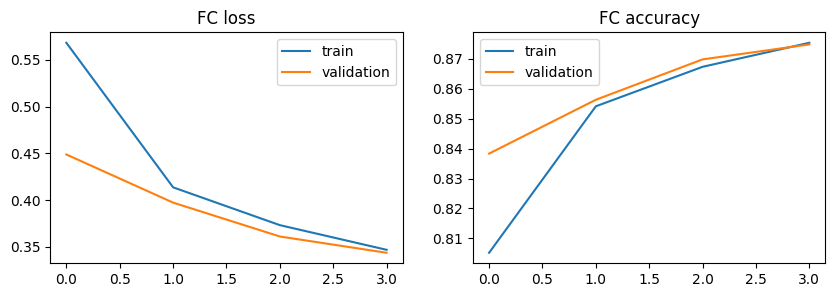

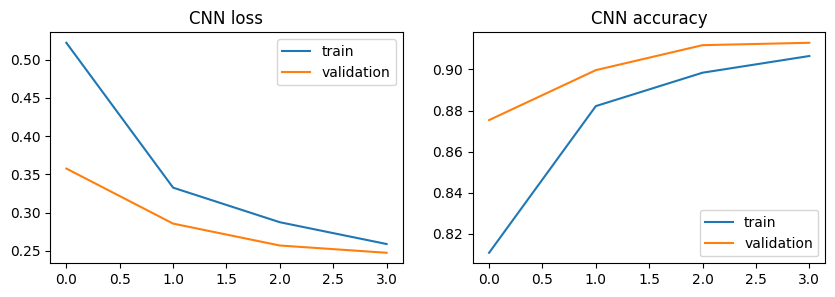

,model,parameters,test_accuracy,test_loss,training_seconds
0,FC,101770,0.8573,0.391120,12.184727
1,CNN,220234,0.8953,0.281366,288.238008


Saved Q5_FC_vs_CNN.csv
FC first-layer parameters: 100480
CNN first-layer parameters: 320
For 28x28 input, K=3, P=1, S=1: output = floor((28+2-3)/1)+1 = 28; output shape 28x28x32.


In [8]:
(x5,y5),(xt,yt)=keras.datasets.fashion_mnist.load_data()
x5=(x5.astype("float32")/255.)[...,None]; xt=(xt.astype("float32")/255.)[...,None]
x5tr,x5v,y5tr,y5v=train_test_split(x5,y5,test_size=.1,stratify=y5,random_state=SEED)
def fc5():
    i=keras.Input((28,28,1)); x=layers.Flatten()(i); x=layers.Dense(128,activation="relu")(x)
    o=layers.Dense(10,activation="softmax")(x); m=keras.Model(i,o)
    m.compile("adam","sparse_categorical_crossentropy",metrics=["accuracy"]); return m
def cnn5():
    i=keras.Input((28,28,1)); x=layers.Conv2D(32,3,padding="same",activation="relu")(i)
    x=layers.MaxPooling2D()(x); x=layers.Conv2D(64,3,padding="same",activation="relu")(x)
    x=layers.MaxPooling2D()(x); x=layers.Flatten()(x); x=layers.Dense(64,activation="relu")(x)
    o=layers.Dense(10,activation="softmax")(x); m=keras.Model(i,o)
    m.compile("adam","sparse_categorical_crossentropy",metrics=["accuracy"]); return m
q5models={}; q5rows=[]
for name,build in [("FC",fc5),("CNN",cnn5)]:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED); m=build()
    st=time.time(); h=m.fit(x5tr,y5tr,validation_data=(x5v,y5v),epochs=4,batch_size=128,verbose=0)
    loss,acc=m.evaluate(xt,yt,verbose=0)
    q5rows.append(dict(model=name,parameters=m.count_params(),test_accuracy=acc,test_loss=loss,training_seconds=time.time()-st))
    q5models[name]=m; plot_hist(h,name)
export(pd.DataFrame(q5rows),"Q5_FC_vs_CNN.csv")
print("FC first-layer parameters:",28*28*1*128+128)
print("CNN first-layer parameters:",3*3*1*32+32)
print("For 28x28 input, K=3, P=1, S=1: output = floor((28+2-3)/1)+1 = 28; output shape 28x28x32.")

,model,normal_accuracy,shifted_accuracy,drop
0,FC,0.8573,0.3587,0.4986
1,CNN,0.8953,0.6133,0.2820


Saved Q5_translation_test.csv


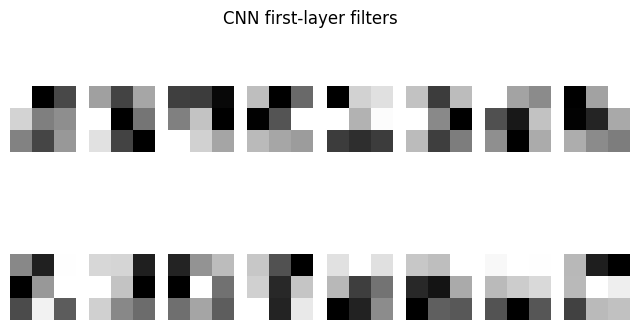

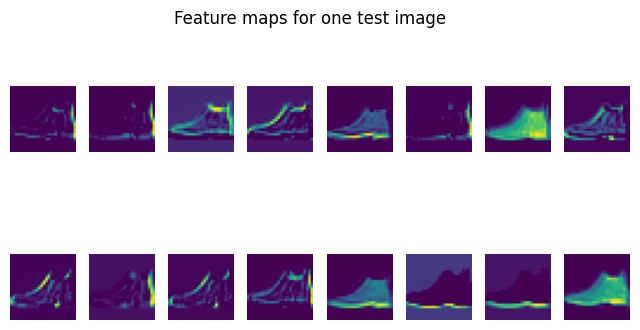

Weight sharing means the same detector scans all image locations; a learned local pattern can therefore activate at a new position. Convolution is translation-equivariant, not perfectly invariant.


In [9]:
def shift_right(im,p=3):
    z=np.zeros_like(im); z[:,:,p:,:]=im[:,:,:-p,:]; return z
trans=[]
for name,m in q5models.items():
    normal=m.evaluate(xt,yt,verbose=0)[1]; shifted=m.evaluate(shift_right(xt),yt,verbose=0)[1]
    trans.append(dict(model=name,normal_accuracy=normal,shifted_accuracy=shifted,drop=normal-shifted))
export(pd.DataFrame(trans),"Q5_translation_test.csv")
cnn=q5models["CNN"]; conv=next(l for l in cnn.layers if isinstance(l,layers.Conv2D))
filt=conv.get_weights()[0]
plt.figure(figsize=(8,4))
for i in range(16):
    plt.subplot(2,8,i+1); plt.imshow(filt[:,:,0,i],cmap="gray"); plt.axis("off")
plt.suptitle("CNN first-layer filters"); plt.show()
fm=keras.Model(cnn.input,conv.output).predict(xt[:1],verbose=0)[0]
plt.figure(figsize=(8,4))
for i in range(16):
    plt.subplot(2,8,i+1); plt.imshow(fm[:,:,i]); plt.axis("off")
plt.suptitle("Feature maps for one test image"); plt.show()
print("Weight sharing means the same detector scans all image locations; a learned local pattern can therefore activate at a new position. Convolution is translation-equivariant, not perfectly invariant.")

# Q6 – Architecture Capacity, Cost and Deployment Boundary (8 marks)

A student-designed CNN family varies depth, width and input resolution. For a convolution: parameters `K²CinCout+Cout`; MACs `Hout×Wout×Cout×K²Cin`. Receptive field recurrence: `r_l=r_(l−1)+(K_l−1)j_(l−1)`, `j_l=j_(l−1)s_l`, starting at `r=j=1`. Doubling width often makes convolution MACs about 4× because both channel dimensions grow; doubling each spatial dimension makes MACs about 4×; doubling same-cost depth makes total cost about 2×.

In [10]:
def q6build(size,width,depth):
    i=keras.Input((size,size,1)); x=i
    for j in range(depth):
        x=layers.Conv2D(width*(2**min(j,2)),3,padding="same",activation="relu",name=f"conv{j+1}")(x)
        x=layers.MaxPooling2D(2,name=f"pool{j+1}")(x)
    x=layers.GlobalAveragePooling2D()(x); o=layers.Dense(10,activation="softmax")(x)
    m=keras.Model(i,o); m.compile("adam","sparse_categorical_crossentropy",metrics=["accuracy"]); return m
def q6cost(m,size):
    h=w=size; ci=1; rf=1; jump=1; macsum=0; rows=[]
    for l in m.layers:
        if isinstance(l,layers.Conv2D):
            k=l.kernel_size[0]; co=l.filters; ho=int(math.ceil(h/l.strides[0])); wo=int(math.ceil(w/l.strides[0]))
            par=k*k*ci*co+co; mac=ho*wo*co*k*k*ci
            rf += (k-1)*jump; jump*=l.strides[0]
            rows.append(dict(layer=l.name,output=f"{ho}x{wo}x{co}",parameters=par,MACs=mac,receptive_field=rf))
            macsum+=mac; h,w,ci=ho,wo,co
        elif isinstance(l,layers.MaxPooling2D):
            s=l.strides[0] if l.strides else l.pool_size[0]; h=int(math.ceil(h/s)); w=int(math.ceil(w/s)); jump*=s
    return pd.DataFrame(rows),macsum
# Hand check for one conv: 28x28x1 -> 3x3 conv, 8 filters, same padding -> 28x28x8
small=q6build(28,8,1); hand,mac=q6cost(small,28); small.summary(); display(hand)
print("Hand first-conv params:",3*3*1*8+8,"Framework total params:",small.count_params())
q6spec=[("Tiny",28,8,1),("Balanced",28,16,2),("Larger",28,32,3)]
q6rows=[]
for name,size,width,depth in q6spec:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED); m=q6build(size,width,depth)
    xx=tf.image.resize(x5tr[:20000],(size,size)).numpy()
    xv=tf.image.resize(x5v[:3000],(size,size)).numpy()
    xts=tf.image.resize(xt,(size,size)).numpy()
    st=time.time(); m.fit(xx,y5tr[:20000],validation_data=(xv,y5v[:3000]),epochs=3,batch_size=128,verbose=0)
    start=time.time(); m.predict(xts[:256],verbose=0); ms=(time.time()-start)/256*1000
    loss,acc=m.evaluate(xts,yt,verbose=0); lt,macs=q6cost(m,size)
    fn=f"q6_{name.lower()}.keras"; m.save(fn); mb=os.path.getsize(fn)/1024**2
    q6rows.append(dict(architecture=name,resolution=size,width=width,depth=depth,parameters=m.count_params(),
                       conv_MACs=macs,file_MB=mb,inference_ms_per_image=ms,test_accuracy=acc))
q6df=pd.DataFrame(q6rows); export(q6df,"Q6_architecture_family.csv")
print("Scaling illustration: width doubled ≈4x conv MACs; H and W doubled ≈4x; same-cost depth doubled ≈2x.")
r=1
for nlayer in range(1,6):
    r+=2; print("After",nlayer,"stride-1 3x3 conv layers receptive field",r,"x",r)
# Explicit illustrative budget, compare measured results
q6df["within_2M_parameters"]=q6df.parameters<=2_000_000
q6df["within_5ms_colab"]=q6df.inference_ms_per_image<=5
q6df["within_both"]=q6df.within_2M_parameters & q6df.within_5ms_colab
display(q6df)
print("The 2M-parameter/5ms budget is an illustrative classroom threshold, not a validated camera-trap device specification. Benchmark on the target hardware before deployment.")

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 28, 28, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │            90 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170 (680.00 B)

 Trainable params: 170 (680.00 B)

 Non-trainable params: 0 (0.00 B)

,layer,output,parameters,MACs,receptive_field
0,conv1,28x28x8,80,56448,3


Hand first-conv params: 80 Framework total params: 170


,architecture,resolution,width,depth,parameters,conv_MACs,file_MB,inference_ms_per_image,test_accuracy
0,Tiny,28,8,1,170,56448,0.028859,0.650140,0.1720
1,Balanced,28,16,2,5130,1016064,0.092578,0.719500,0.6149
2,Larger,28,32,3,93962,7451136,1.116757,1.424179,0.7960


Saved Q6_architecture_family.csv
Scaling illustration: width doubled ≈4x conv MACs; H and W doubled ≈4x; same-cost depth doubled ≈2x.
After 1 stride-1 3x3 conv layers receptive field 3 x 3
After 2 stride-1 3x3 conv layers receptive field 5 x 5
After 3 stride-1 3x3 conv layers receptive field 7 x 7
After 4 stride-1 3x3 conv layers receptive field 9 x 9
After 5 stride-1 3x3 conv layers receptive field 11 x 11


,architecture,resolution,width,depth,parameters,conv_MACs,file_MB,inference_ms_per_image,test_accuracy,within_2M_parameters,within_5ms_colab,within_both
0,Tiny,28,8,1,170,56448,0.028859,0.650140,0.1720,True,True,True
1,Balanced,28,16,2,5130,1016064,0.092578,0.719500,0.6149,True,True,True
2,Larger,28,32,3,93962,7451136,1.116757,1.424179,0.7960,True,True,True


The 2M-parameter/5ms budget is an illustrative classroom threshold, not a validated camera-trap device specification. Benchmark on the target hardware before deployment.


# Q7 – Diagnose, Redesign and Validate (13 marks)

Candidate limitation: deep sigmoid network from Q1. Diagnosis hypothesis: products of sigmoid derivatives shrink gradients in early layers. Redesign: ReLU hidden units + He initialization. Objective: increase first-layer gradient norm without materially reducing validation/test accuracy, using the same data, split, seed and six-epoch budget. The experiment below tests this prediction; it does not assume the redesign wins.

,model,first_gradient,last_gradient,train_loss,val_loss,val_accuracy,test_accuracy,parameters,seconds
0,Original deep sigmoid,0.000004,0.359196,0.370405,0.371875,0.8775,0.8775,8097,3.781474
1,Redesigned ReLU + He,0.217693,0.976687,0.169951,0.233391,0.9100,0.9350,8097,4.629602


Saved Q7_original_vs_redesigned.csv


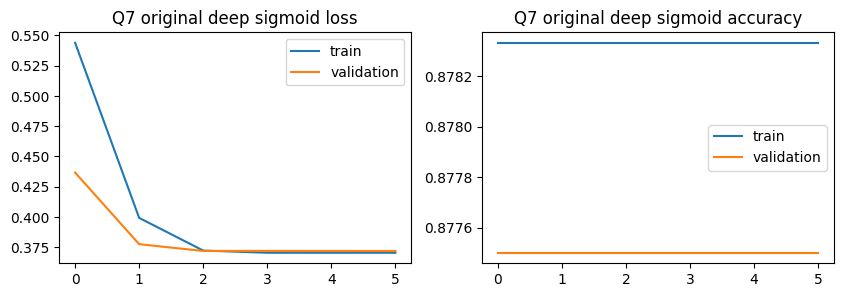

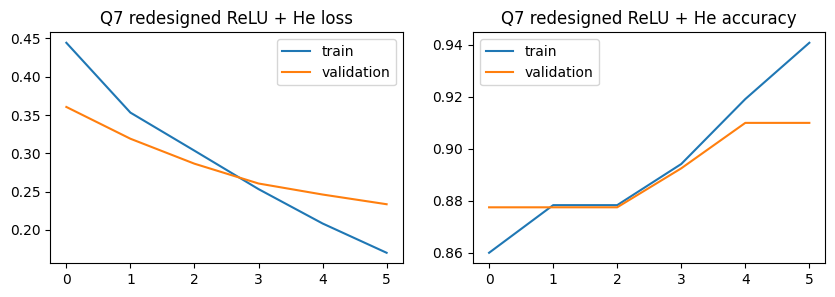

First-gradient ratio redesigned/original: 56216.44311161972
Validation accuracy change: 0.03250002861022949
Parameter difference: 0 training-time difference: 0.8481278419494629


In [11]:
def q7train(act,label):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    m=q1build(act,8,False); g=q1grads(m); st=time.time()
    h=m.fit(X1tr,y1tr,validation_data=(X1v,y1v),epochs=6,batch_size=64,verbose=0)
    p=m.predict(X1te,verbose=0).ravel()
    return m,h,dict(model=label,first_gradient=g["h1"],last_gradient=g["h8"],
        train_loss=h.history["loss"][-1],val_loss=h.history["val_loss"][-1],
        val_accuracy=m.evaluate(X1v,y1v,verbose=0)[1],test_accuracy=metrics_binary(y1te,p)["accuracy"],
        parameters=m.count_params(),seconds=time.time()-st)
mo,ho,ro=q7train("sigmoid","Original deep sigmoid")
mr,hr,rr=q7train("relu","Redesigned ReLU + He")
q7df=pd.DataFrame([ro,rr]); export(q7df,"Q7_original_vs_redesigned.csv")
plot_hist(ho,"Q7 original deep sigmoid"); plot_hist(hr,"Q7 redesigned ReLU + He")
print("First-gradient ratio redesigned/original:",rr["first_gradient"]/(ro["first_gradient"]+1e-12))
print("Validation accuracy change:",rr["val_accuracy"]-ro["val_accuracy"])
print("Parameter difference:",rr["parameters"]-ro["parameters"],"training-time difference:",rr["seconds"]-ro["seconds"])

# Final evidence export and submission checklist

CSV files created:
- Q1 activation comparison, layer-wise gradients and inactive ReLU fraction
- Q2 gradient-check bug evidence
- Q3 condition and regularizer comparisons
- Q4 optimizer experiments
- Q5 FC/CNN and translation comparison
- Q6 architecture family
- Q7 original/redesigned comparison

**Before submitting:** retain all cell outputs and plots; report dataset sizes, splits, seed, hyperparameters, Colab runtime, and any changes. Include mathematical derivations and discuss limitations. Layer-wise gradients, loss curves, parameter counts and MACs are primary evidence; accuracy/time alone are insufficient. The assignment may include a viva, so understand each code section and be prepared to explain it.

In [12]:
files=sorted(glob.glob("Q*.csv"))
with zipfile.ZipFile("CO2_Assignment_Evidence_CSVs.zip","w",zipfile.ZIP_DEFLATED) as z:
    for f in files: z.write(f)
print("Evidence files:",files)
print("Created CO2_Assignment_Evidence_CSVs.zip")

Evidence files: ['Q1_activation_results.csv', 'Q1_layer_gradient_norms.csv', 'Q1_relu_inactive_fraction.csv', 'Q2_bug_gradient_check.csv', 'Q3_conditions.csv', 'Q3_regularizer_comparison.csv', 'Q4_optimizer_experiments.csv', 'Q5_FC_vs_CNN.csv', 'Q5_translation_test.csv', 'Q6_architecture_family.csv', 'Q7_original_vs_redesigned.csv']
Created CO2_Assignment_Evidence_CSVs.zip
